In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
import time
import tracemalloc
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
print("Library siap.")

Library siap.


In [2]:
df = pd.read_csv('properti_multi_kota.csv')
print("Shape awal:", df.shape)
df.head()

Shape awal: (64650, 8)


,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


In [3]:
SAMPLE_SIZE  = 15_000
RANDOM_STATE = 42

df['sumber_data'] = df['sumber'].str.split('/').str[0]

pct_usia = df['usia_bangunan'].isnull().mean() * 100
df = df.drop(columns=['sumber', 'usia_bangunan'])
print(f"[1] Drop usia_bangunan   : {pct_usia:.1f}% kosong -> kolom dibuang")

before = len(df)
df = df.drop_duplicates()
print(f"[2] Hapus duplikat       : {before} -> {len(df)}")

df['lokasi'] = df['lokasi'].str.strip().str.title()

numeric_cols = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'harga']
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())
print(f"[3] Missing values diisi  : {df[numeric_cols].isnull().sum().sum()} tersisa")

before = len(df)
df = df[df['harga'].between(50_000_000, 50_000_000_000)]
df = df[df['luas_m2'].between(10, 5000)]
df = df[df['luas_bangunan'].between(10, 2000)]
df = df[df['jumlah_kamar'].between(0, 20)]
df = df[df['jumlah_kamar_mandi'].between(0, 20)]
print(f"[4] Hapus outlier ekstrem : {before} -> {len(df)}")

median_harga = df['harga'].median()
df['kategori_harga'] = np.where(df['harga'] > median_harga, 'Mahal', 'Murah')

df = df.sample(n=SAMPLE_SIZE, random_state=RANDOM_STATE).reset_index(drop=True)
print(f"[5] Sampling              : {SAMPLE_SIZE} data (random_state={RANDOM_STATE})")

FEATURES = ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'harga']
X = df[FEATURES].copy()
for col in ['luas_m2', 'luas_bangunan', 'harga']:
    X[col] = np.log1p(X[col])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(f"[6] Data siap clustering  : {X_scaled.shape}")
print(f"[7] Fitur                 : {FEATURES}")

[1] Drop usia_bangunan   : 92.6% kosong -> kolom dibuang
[2] Hapus duplikat       : 64650 -> 57217
[3] Missing values diisi  : 0 tersisa
[4] Hapus outlier ekstrem : 57217 -> 56173
[5] Sampling              : 15000 data (random_state=42)
[6] Data siap clustering  : (15000, 5)
[7] Fitur                 : ['luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi', 'harga']


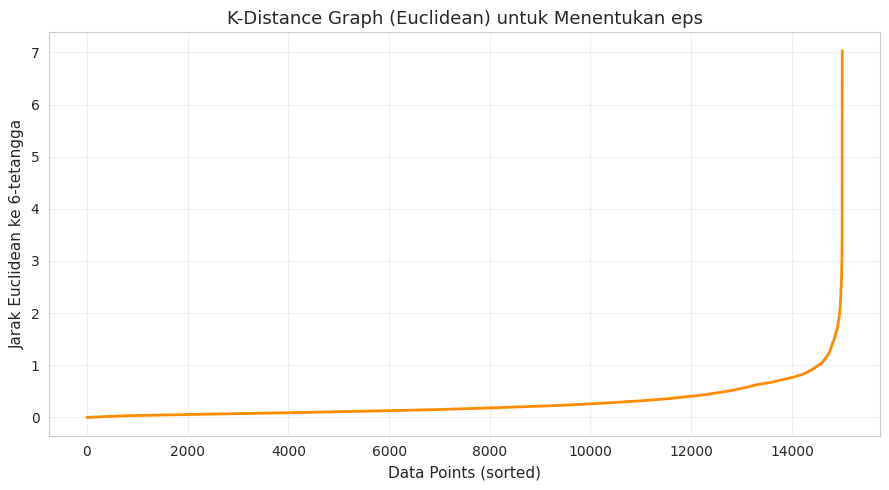

Kandidat eps berdasarkan persentil:
  Persentil 85: 0.5088
  Persentil 90: 0.6584
  Persentil 92: 0.7215
  Persentil 95: 0.8445
  Persentil 97: 1.0099


In [4]:
MIN_SAMPLES = 6  # sama dengan Manhattan agar fair

neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric='euclidean')
distances, _ = neighbors.fit(X_scaled).kneighbors(X_scaled)
distances = np.sort(distances[:, -1])

plt.figure(figsize=(9, 5))
plt.plot(distances, color='darkorange', linewidth=2)
plt.xlabel('Data Points (sorted)', fontsize=11)
plt.ylabel(f'Jarak Euclidean ke {MIN_SAMPLES}-tetangga', fontsize=11)
plt.title('K-Distance Graph (Euclidean) untuk Menentukan eps', fontsize=13)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Kandidat eps berdasarkan persentil:")
for p in [85, 90, 92, 95, 97]:
    print(f"  Persentil {p}: {np.percentile(distances, p):.4f}")

In [5]:
print(f"min_samples = {MIN_SAMPLES}")
print(f"{'eps':>7} | {'cluster':>7} | {'noise':>5} | keterangan")
print("-" * 52)
for eps_c in np.arange(0.70, 0.801, 0.01).round(3):
    lab = DBSCAN(eps=eps_c, min_samples=MIN_SAMPLES, metric='euclidean').fit_predict(X_scaled)
    nc = len(set(lab)) - (1 if -1 in lab else 0)
    nn = list(lab).count(-1)
    ket = "<== 3 cluster (target tercapai)" if nc == 3 else ""
    print(f"{eps_c:>7} | {nc:>7} | {nn:>5} | {ket}")

min_samples = 6
    eps | cluster | noise | keterangan
----------------------------------------------------
    0.7 |      11 |   884 | 
   0.71 |      11 |   841 | 
   0.72 |      10 |   818 | 
   0.73 |       2 |   774 | 
   0.74 |       1 |   737 | 
   0.75 |       3 |   694 | <== 3 cluster (target tercapai)
   0.76 |       5 |   658 | 
   0.77 |       3 |   631 | <== 3 cluster (target tercapai)
   0.78 |       4 |   603 | 
   0.79 |       4 |   580 | 
    0.8 |       3 |   558 | <== 3 cluster (target tercapai)


In [6]:
EPS_VALUE = 0.75

tracemalloc.start()
start_time = time.time()

dbscan = DBSCAN(eps=EPS_VALUE, min_samples=MIN_SAMPLES, metric='euclidean')
labels = dbscan.fit_predict(X_scaled)

exec_time = time.time() - start_time
_, peak = tracemalloc.get_traced_memory()
tracemalloc.stop()

df['cluster'] = labels
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)

print("="*55)
print("HASIL DBSCAN (EUCLIDEAN)")
print("="*55)
print(f"eps                  : {EPS_VALUE}")
print(f"min_samples          : {MIN_SAMPLES}")
print(f"Jumlah cluster       : {n_clusters}")
print(f"Jumlah noise/outlier : {n_noise} ({n_noise/len(df)*100:.2f}%)")
print(f"Waktu eksekusi       : {exec_time:.4f} detik")
print(f"Peak memory          : {peak/1024:.2f} KB")
print("\nDistribusi cluster:")
print(df['cluster'].value_counts().sort_index())

HASIL DBSCAN (EUCLIDEAN)
eps                  : 0.75
min_samples          : 6
Jumlah cluster       : 3
Jumlah noise/outlier : 694 (4.63%)
Waktu eksekusi       : 2.2400 detik
Peak memory          : 4960.67 KB

Distribusi cluster:
cluster
-1      694
 0    14295
 1        7
 2        4
Name: count, dtype: int64


In [7]:
cluster_only = df[df['cluster'] != -1]
print("Rata-rata fitur per cluster (tanpa noise):")
print(cluster_only.groupby('cluster')[FEATURES].mean().round(2))

Rata-rata fitur per cluster (tanpa noise):
         luas_m2  luas_bangunan  jumlah_kamar  jumlah_kamar_mandi  \
cluster                                                             
0         139.10          98.33          2.57                1.82   
1         762.00         739.29          8.00                5.29   
2         260.75         209.50          0.50                1.00   

                harga  
cluster                
0        1.324836e+09  
1        1.033571e+10  
2        3.718875e+09  


In [8]:
top_lokasi = df['lokasi'].value_counts().head(10).index
print("Distribusi 10 lokasi terbanyak per cluster:")
print(pd.crosstab(df['cluster'], df.loc[df['lokasi'].isin(top_lokasi), 'lokasi']))

print("\nDistribusi sumber data per cluster:")
print(pd.crosstab(df['cluster'], df['sumber_data']))

print("\nDistribusi kategori harga per cluster:")
print(pd.crosstab(df['cluster'], df['kategori_harga']))

Distribusi 10 lokasi terbanyak per cluster:
lokasi   Bekasi  Depok  Kabupaten Bandung  Kabupaten Bekasi  Kabupaten Bogor  \
cluster                                                                        
-1            4      4                  1                 6                2   
 0          494    388                414               487              526   

lokasi   Kabupaten Sidoarjo  Kabupaten Tangerang  Semarang  Surabaya  \
cluster                                                                
-1                        5                    3        11        31   
 0                      451                  469       323       355   

lokasi   Tangerang Selatan  
cluster                     
-1                       3  
 0                     416  

Distribusi sumber data per cluster:
sumber_data  99.co  ColectDataRumah  FLUS  Pinhome  rumah123  uas-properti
cluster                                                                   
-1             406                1    59  

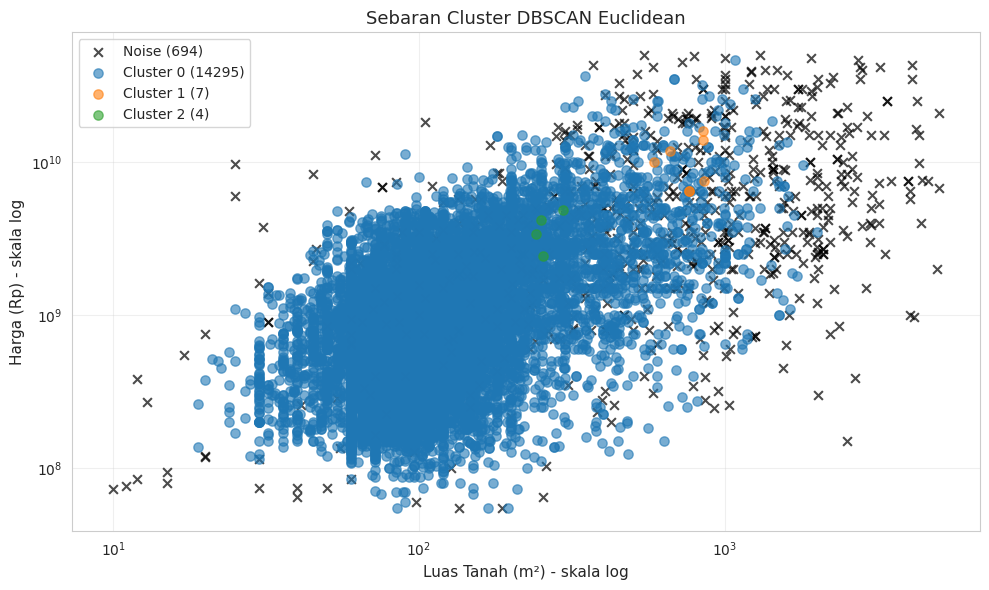

In [9]:
plt.figure(figsize=(10, 6))
for label in sorted(df['cluster'].unique()):
    subset = df[df['cluster'] == label]
    if label == -1:
        plt.scatter(subset['luas_m2'], subset['harga'], c='black', marker='x',
                    s=40, alpha=0.7, label=f'Noise ({len(subset)})')
    else:
        plt.scatter(subset['luas_m2'], subset['harga'], s=45, alpha=0.6,
                    label=f'Cluster {label} ({len(subset)})')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Luas Tanah (m²) - skala log', fontsize=11)
plt.ylabel('Harga (Rp) - skala log', fontsize=11)
plt.title('Sebaran Cluster DBSCAN Euclidean', fontsize=13)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

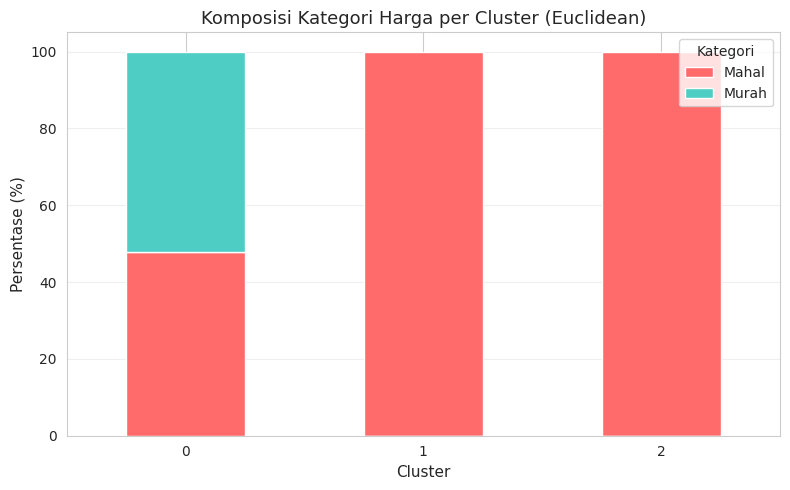

Persentase kategori harga per cluster (%):
kategori_harga  Mahal  Murah
cluster                     
0                47.9   52.1
1               100.0    0.0
2               100.0    0.0


In [10]:
comp = pd.crosstab(cluster_only['cluster'], cluster_only['kategori_harga'],
                   normalize='index') * 100

comp.plot(kind='bar', stacked=True, figsize=(8, 5),
          color=['#FF6B6B', '#4ECDC4'], edgecolor='white')
plt.xlabel('Cluster', fontsize=11)
plt.ylabel('Persentase (%)', fontsize=11)
plt.title('Komposisi Kategori Harga per Cluster (Euclidean)', fontsize=13)
plt.legend(title='Kategori', loc='upper right')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

print("Persentase kategori harga per cluster (%):")
print(comp.round(2))

In [11]:
mask = df['cluster'] != -1
sil_score = silhouette_score(X_scaled[mask], df.loc[mask, 'cluster'], metric='euclidean')
print(f"Silhouette Score (Euclidean): {sil_score:.4f}")

Silhouette Score (Euclidean): 0.2664


In [12]:
hasil_dbscan = {
    'Metode'              : 'DBSCAN',
    'Distance Metric'     : 'Euclidean',
    'Jumlah Cluster'      : n_clusters,
    'Jumlah Noise'        : n_noise,
    'Waktu Eksekusi (s)'  : round(exec_time, 4),
    'Peak Memory (KB)'    : round(peak / 1024, 2),
    'Silhouette Score'    : round(sil_score, 4),
    'Parameter'           : f'eps={EPS_VALUE}, min_samples={MIN_SAMPLES}'
}
pd.DataFrame([hasil_dbscan]).T

,0
Metode,DBSCAN
Distance Metric,Euclidean
Jumlah Cluster,3
Jumlah Noise,694
Waktu Eksekusi (s),2.24
Peak Memory (KB),4960.67
Silhouette Score,0.2664
Parameter,"eps=0.75, min_samples=6"
